# 04 — Operations Analysis

## tl;dr

This notebook turns demand evidence into operational diagnostics: stable/volatile family segments, store performance profiles, promotion dependence indicators, and peak-demand windows. Recommendations are framed as planning actions, not precise inventory optimization.

## Context & Methods

Demand variability is measured on daily aggregates using coefficient of variation (CV = standard deviation / mean). Median demand and median CV create transparent four-quadrant family segments. These are relative portfolio segments, not universal industry thresholds.

In [1]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# Resolve the repository root dynamically so the notebook works from either
# the project root or the notebooks directory without a local absolute path.
candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (candidate, *candidate.parents)
    if (path / "data").is_dir() and (path / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DATA_DIR = PROJECT_ROOT / "outputs" / "processed_data"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in (PROCESSED_DATA_DIR, OUTPUT_DATA_DIR, FIGURE_DIR, TABLE_DIR):
    # Creating output folders is safe; raw source files are never modified.
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.data_loader import load_all_available
from src.preprocessing import build_analysis_panel
from src.visualization import PROJECT_COLORS, save_figure, set_project_style

set_project_style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
datasets = load_all_available(RAW_DATA_DIR)
panel = build_analysis_panel(datasets)

## Results

### 1. Family demand variability and operational segments

**Why this step is needed:** Combining demand level with coefficient of variation produces practical portfolio groups: routine high-volume flows, uncertain high-volume flows, and lower-priority stable or volatile categories.

,mean_daily_demand,std_daily_demand,total_sales,cv,demand_level,variability_level,segment
family,,,,,,,
GROCERY I,"203,956.493","61,832.885","343,462,734.886",0.303,High demand,Stable,High demand / Stable
BEVERAGES,"128,832.830","63,121.646","216,954,486.000",0.490,High demand,Stable,High demand / Stable
CLEANING,"57,910.504","15,211.881","97,521,289.000",0.263,High demand,Stable,High demand / Stable
DAIRY,"38,294.364","13,725.805","64,487,709.000",0.358,High demand,Stable,High demand / Stable
BREAD/BAKERY,"25,020.158","6,511.796","42,133,945.576",0.260,High demand,Stable,High demand / Stable
POULTRY,"18,928.744","6,078.422","31,876,004.472",0.321,High demand,Stable,High demand / Stable
MEATS,"18,459.898","4,334.043","31,086,468.404",0.235,High demand,Stable,High demand / Stable
PERSONAL CARE,"14,603.356","5,361.252","24,592,051.000",0.367,High demand,Stable,High demand / Stable
DELI,"14,317.294","4,171.726","24,110,322.469",0.291,High demand,Stable,High demand / Stable


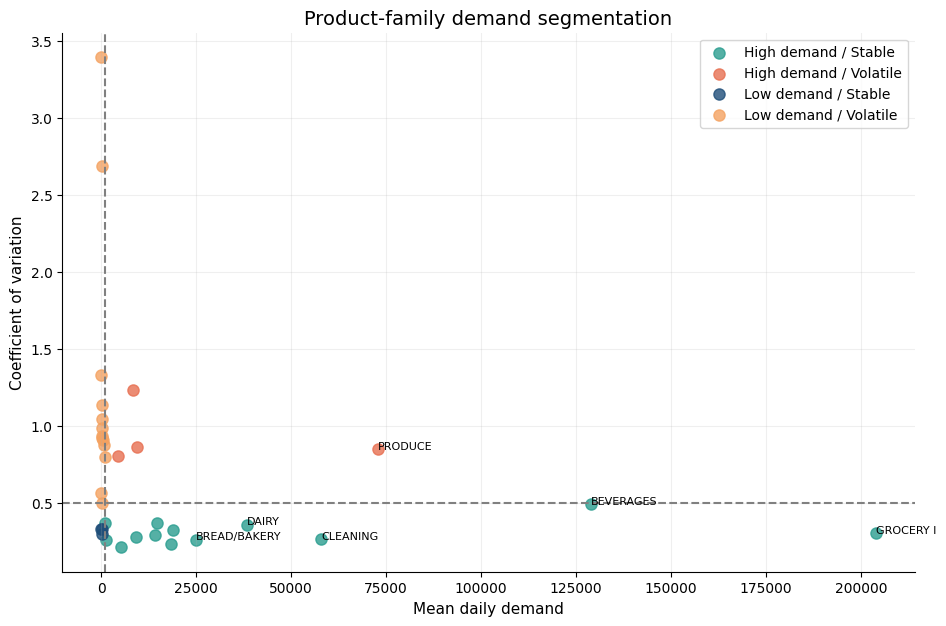

In [3]:
family_daily = panel.groupby(["family", "date"], observed=True)["sales"].sum().reset_index()
family_ops = family_daily.groupby("family", observed=True)["sales"].agg(
    mean_daily_demand="mean", std_daily_demand="std", total_sales="sum"
)
family_ops["cv"] = family_ops["std_daily_demand"] / family_ops["mean_daily_demand"]
demand_cut = family_ops["mean_daily_demand"].median()
cv_cut = family_ops["cv"].median()
family_ops["demand_level"] = np.where(family_ops["mean_daily_demand"].ge(demand_cut), "High demand", "Low demand")
family_ops["variability_level"] = np.where(family_ops["cv"].ge(cv_cut), "Volatile", "Stable")
family_ops["segment"] = family_ops["demand_level"] + " / " + family_ops["variability_level"]
display(family_ops.sort_values(["segment", "total_sales"], ascending=[True, False]))

fig, ax = plt.subplots(figsize=(11, 7))
segment_colors = {
    "High demand / Stable": PROJECT_COLORS[1], "High demand / Volatile": PROJECT_COLORS[4],
    "Low demand / Stable": PROJECT_COLORS[0], "Low demand / Volatile": PROJECT_COLORS[3],
}
for segment, values in family_ops.groupby("segment"):
    ax.scatter(values["mean_daily_demand"], values["cv"], label=segment, s=65, alpha=.8, color=segment_colors[segment])
ax.axvline(demand_cut, color="grey", linestyle="--")
ax.axhline(cv_cut, color="grey", linestyle="--")
for family in family_ops.nlargest(6, "total_sales").index:
    ax.annotate(family, (family_ops.loc[family, "mean_daily_demand"], family_ops.loc[family, "cv"]), fontsize=8)
ax.set(title="Product-family demand segmentation", xlabel="Mean daily demand", ylabel="Coefficient of variation")
ax.legend()
save_figure(fig, FIGURE_DIR, "operations_01_family_segments.png")
plt.show()

### 2. Store performance and operating profiles

**Why this step is needed:** Store planning should reflect scale, variability, traffic, promotion exposure, and lifecycle coverage. The 90% coverage rule prevents later openings from being mislabeled as ordinary volatility.

,average_daily_sales,std_daily_sales,average_daily_transactions,transaction_coverage_pct,promoted_item_days,active_sales_days,observed_days,demand_cv,promotion_active_days_pct,active_sales_days_pct,comparable_store,seasonal_sensitivity,city,state,type,cluster
store_nbr,,,,,,,,,,,,,,,,
44,"36,869.093","14,704.525","4,336.967",99.584,1135,1679,1684,0.399,67.399,99.703,True,1.237,Quito,Pichincha,A,5
45,"32,362.239","13,689.660","3,697.743",99.584,1138,1679,1684,0.423,67.577,99.703,True,1.274,Quito,Pichincha,A,11
47,"30,254.341","12,523.215","3,897.323",99.584,1135,1679,1684,0.414,67.399,99.703,True,1.260,Quito,Pichincha,A,14
3,"29,977.381","11,324.234","3,201.879",99.525,1182,1679,1684,0.378,70.190,99.703,True,1.230,Quito,Pichincha,D,8
49,"25,783.905","11,904.520","2,727.551",99.584,1136,1679,1684,0.462,67.458,99.703,True,1.323,Quito,Pichincha,A,11
46,"24,878.897","11,084.245","3,571.922",99.584,1129,1679,1684,0.446,67.043,99.703,True,1.318,Quito,Pichincha,A,14
48,"21,337.963","10,317.645","3,045.787",99.584,1147,1679,1684,0.484,68.112,99.703,True,1.347,Quito,Pichincha,A,14
51,"19,543.640","6,439.521","1,713.544",99.584,1115,1679,1684,0.329,66.211,99.703,True,1.284,Guayaquil,Guayas,A,17
8,"18,108.246","6,757.231","2,767.286",99.525,1180,1679,1684,0.373,70.071,99.703,True,1.243,Quito,Pichincha,D,8


,average_daily_sales,std_daily_sales,average_daily_transactions,transaction_coverage_pct,promoted_item_days,active_sales_days,observed_days,demand_cv,promotion_active_days_pct,active_sales_days_pct,comparable_store,seasonal_sensitivity,city,state,type,cluster
store_nbr,,,,,,,,,,,,,,,,
52,"1,601.051","5,984.923","2,333.839",7.007,117,118,1684,3.738,6.948,7.007,False,3.122,Manta,Manabi,A,11
22,"2,428.861","3,168.574",751.350,39.846,672,673,1684,1.305,39.905,39.964,False,1.336,Puyo,Pastaza,C,7
42,"5,312.214","6,464.389","1,114.786",42.755,721,722,1684,1.217,42.815,42.874,False,1.258,Cuenca,Azuay,D,2
21,"5,496.144","6,768.344","1,126.860",44.418,749,750,1684,1.231,44.477,44.537,False,1.355,Santo Domingo,Santo Domingo de los Tsachilas,B,6
29,"5,775.034","6,106.545","1,122.938",51.900,876,876,1684,1.057,52.019,52.019,False,1.184,Guayaquil,Guayas,E,10
20,"7,672.776","8,763.811","1,564.949",53.979,909,911,1684,1.142,53.979,54.097,False,1.236,Quito,Pichincha,B,6
53,"6,660.432","5,838.502","1,011.210",69.299,1134,1169,1684,0.877,67.340,69.418,False,1.331,Manta,Manabi,D,13


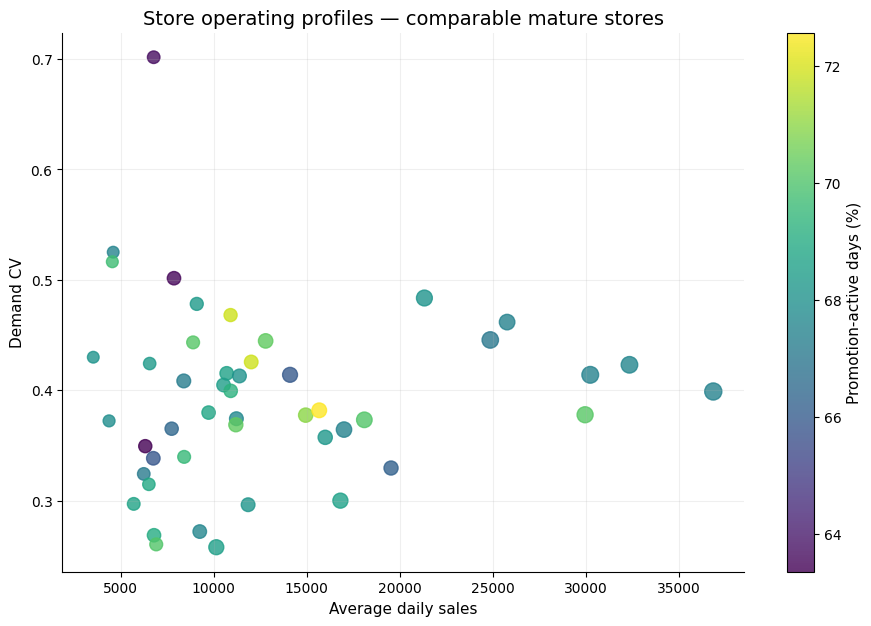

In [4]:
store_daily = panel.groupby(["store_nbr", "date"], observed=True).agg(
    sales=("sales", "sum"), transactions=("transactions", "max"), onpromotion=("onpromotion", "sum")
).reset_index()
store_ops = store_daily.groupby("store_nbr").agg(
    average_daily_sales=("sales", "mean"),
    std_daily_sales=("sales", "std"),
    average_daily_transactions=("transactions", "mean"),
    transaction_coverage_pct=("transactions", lambda values: 100 * values.notna().mean()),
    promoted_item_days=("onpromotion", lambda values: values.gt(0).sum()),
    active_sales_days=("sales", lambda values: values.gt(0).sum()),
    observed_days=("date", "size"),
)
store_ops["demand_cv"] = store_ops["std_daily_sales"] / store_ops["average_daily_sales"]
store_ops["promotion_active_days_pct"] = 100 * store_ops["promoted_item_days"] / store_ops["observed_days"]
store_ops["active_sales_days_pct"] = 100 * store_ops["active_sales_days"] / store_ops["observed_days"]
store_ops["comparable_store"] = (
    store_ops["transaction_coverage_pct"].ge(90)
    & store_ops["active_sales_days_pct"].ge(90)
)

monthly_store = store_daily.assign(month=store_daily["date"].dt.month).groupby(["store_nbr", "month"])["sales"].mean()
store_ops["seasonal_sensitivity"] = monthly_store.groupby("store_nbr").max() / monthly_store.groupby("store_nbr").mean()
store_ops = store_ops.join(datasets["stores.csv"].set_index("store_nbr"))
display(store_ops.sort_values("average_daily_sales", ascending=False).head(15))
display(store_ops.loc[~store_ops["comparable_store"]].sort_values("transaction_coverage_pct"))

fig, ax = plt.subplots(figsize=(11, 7))
comparable_ops = store_ops.loc[store_ops["comparable_store"]]
scatter = ax.scatter(
    comparable_ops["average_daily_sales"], comparable_ops["demand_cv"],
    s=20 + 2 * comparable_ops["average_daily_transactions"].fillna(0) ** .5,
    c=comparable_ops["promotion_active_days_pct"], cmap="viridis", alpha=.8
)
ax.set(title="Store operating profiles — comparable mature stores", xlabel="Average daily sales", ylabel="Demand CV")
fig.colorbar(scatter, ax=ax, label="Promotion-active days (%)")
save_figure(fig, FIGURE_DIR, "operations_02_store_profiles.png")
plt.show()

### 3. Promotion planning indicators

**Why this step is needed:** Promotion-associated demand differs by family, so category-specific ratios can prioritize staffing and replenishment coordination while avoiding unsupported causal-lift claims.

,mean_not_promoted,mean_promoted,observed_ratio,promoted_observations,segment,total_sales
family,,,,,,
SCHOOL AND OFFICE SUPPLIES,1.022,44.529,43.570,"4,054.000",Low demand / Volatile,"269,316.000"
BABY CARE,0.110,1.660,15.146,53.000,Low demand / Volatile,"10,051.000"
PET SUPPLIES,3.507,15.835,4.515,"3,053.000",Low demand / Volatile,"356,584.000"
HOME AND KITCHEN II,10.275,41.158,4.006,"18,984.000",Low demand / Volatile,"1,520,670.000"
PRODUCE,792.102,"2,438.220",3.078,"30,784.000",High demand / Volatile,"122,704,684.676"
HOME APPLIANCES,0.457,1.397,3.057,58.000,Low demand / Volatile,"41,601.000"
LAWN AND GARDEN,5.511,16.787,3.046,"4,232.000",Low demand / Volatile,"548,842.000"
HOME CARE,101.956,309.445,3.035,"32,538.000",High demand / Volatile,"16,022,744.000"
PLAYERS AND ELECTRONICS,6.082,17.364,2.855,849.000,Low demand / Volatile,"562,608.000"


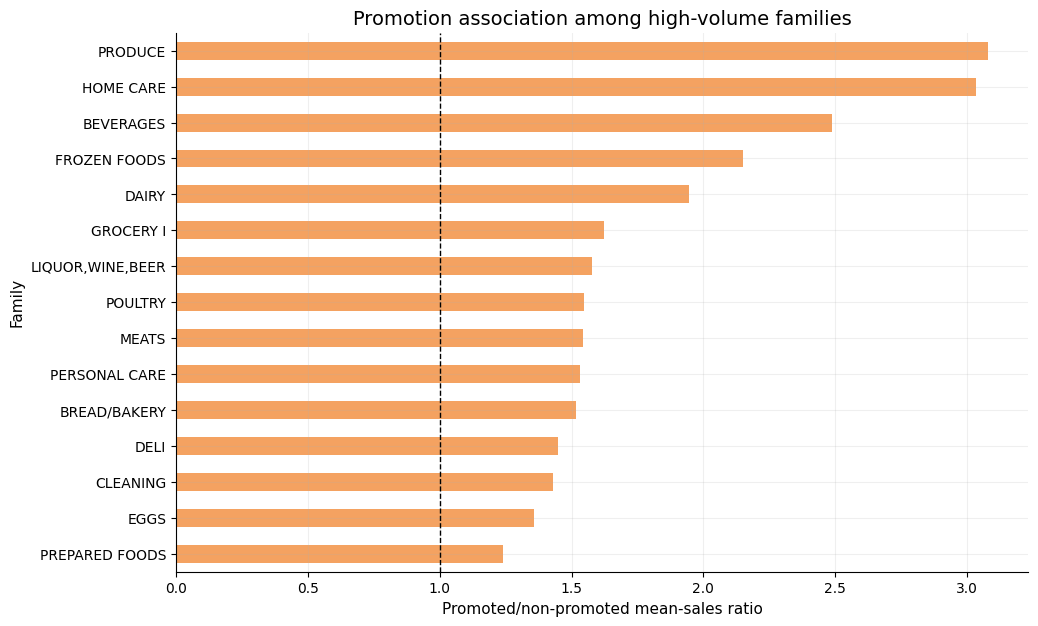

In [5]:
promo = panel.assign(promoted=panel["onpromotion"].gt(0)).groupby(
    ["family", "promoted"], observed=True
)["sales"].agg(["mean", "median", "count"]).unstack()
promo_metrics = pd.DataFrame(index=promo.index)
promo_metrics["mean_not_promoted"] = promo[("mean", False)]
promo_metrics["mean_promoted"] = promo[("mean", True)]
promo_metrics["observed_ratio"] = promo_metrics["mean_promoted"] / promo_metrics["mean_not_promoted"].replace(0, np.nan)
promo_metrics["promoted_observations"] = promo[("count", True)]
promo_metrics = promo_metrics.join(family_ops[["segment", "total_sales"]])
display(promo_metrics.sort_values("observed_ratio", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(11, 7))
promo_metrics.nlargest(15, "total_sales").sort_values("observed_ratio")["observed_ratio"].plot(
    kind="barh", ax=ax, color=PROJECT_COLORS[3]
)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set(title="Promotion association among high-volume families", xlabel="Promoted/non-promoted mean-sales ratio", ylabel="Family")
save_figure(fig, FIGURE_DIR, "operations_03_promotion_planning.png")
plt.show()

### 4. Peak-demand calendar for staffing and capacity

**Why this step is needed:** Recurring weekday and monthly peaks translate demand history into concrete reviews of labor, checkout, receiving, shelf replenishment, and supplier capacity.

,mean,std
weekday,,
Sunday,"825,218.122","257,472.921"
Saturday,"772,205.594","221,747.538"
Monday,"617,542.713","202,901.446"
Wednesday,"593,244.553","206,976.013"
Friday,"579,574.361","191,907.915"
Tuesday,"569,926.088","199,672.002"
Thursday,"505,269.201","168,677.995"


,mean,std
month,,
12,"808,565.340","226,189.237"
11,"669,464.901","215,148.327"
7,"666,858.456","214,114.782"
10,"645,809.509","224,283.454"
9,"645,613.999","208,425.895"
6,"630,111.355","227,399.443"
3,"627,280.562","217,025.088"
1,"609,304.208","268,236.797"
5,"609,026.690","241,142.625"


,mean,median,std,count
is_holiday,,,,
False,"627,095.803","624,910.026","227,733.997",1441
True,"699,588.068","685,673.075","262,714.980",243


,mean,median,count
onpromotion,,,
"(-0.001, 2300.0]","509,860.191","463,132.406",843
"(2300.0, 8397.25]","702,677.228","665,484.316",420
"(8397.25, 26861.0]","828,285.927","777,620.954",421


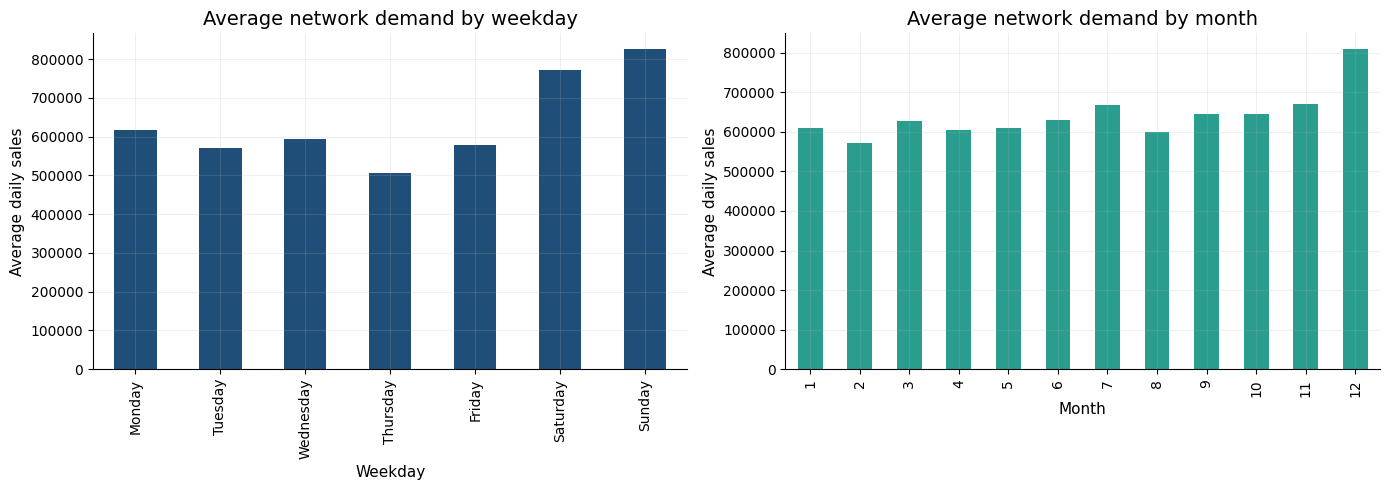

In [6]:
network_daily = panel.groupby("date", observed=True).agg(
    sales=("sales", "sum"), is_holiday=("is_holiday", "max"), onpromotion=("onpromotion", "sum")
).reset_index()
network_daily["weekday"] = network_daily["date"].dt.day_name()
network_daily["month"] = network_daily["date"].dt.month
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

peak_weekdays = network_daily.groupby("weekday")["sales"].agg(["mean", "std"]).reindex(weekday_order)
peak_months = network_daily.groupby("month")["sales"].agg(["mean", "std"])
holiday_peak = network_daily.groupby("is_holiday")["sales"].agg(["mean", "median", "std", "count"])
promotion_bins = pd.qcut(network_daily["onpromotion"], 4, duplicates="drop")
promotion_peak = network_daily.groupby(promotion_bins, observed=True)["sales"].agg(["mean", "median", "count"])
display(peak_weekdays.sort_values("mean", ascending=False))
display(peak_months.sort_values("mean", ascending=False))
display(holiday_peak)
display(promotion_peak)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
peak_weekdays["mean"].plot(kind="bar", ax=axes[0], color=PROJECT_COLORS[0])
axes[0].set(title="Average network demand by weekday", xlabel="Weekday", ylabel="Average daily sales")
peak_months["mean"].plot(kind="bar", ax=axes[1], color=PROJECT_COLORS[1])
axes[1].set(title="Average network demand by month", xlabel="Month", ylabel="Average daily sales")
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "operations_04_peak_calendar.png")
plt.show()

### 5. Save operational evidence tables

**Why this step is needed:** The final insight notebook should read small, reviewed evidence tables rather than repeat heavy transformations or depend on hidden notebook state.

In [7]:
family_ops.reset_index().to_csv(TABLE_DIR / "family_operations_segments.csv", index=False)
store_ops.reset_index().to_csv(TABLE_DIR / "store_operations_summary.csv", index=False)
promo_metrics.reset_index().to_csv(TABLE_DIR / "promotion_operations_summary.csv", index=False)
peak_weekdays.reset_index().to_csv(TABLE_DIR / "peak_weekdays.csv", index=False)
peak_months.reset_index().to_csv(TABLE_DIR / "peak_months.csv", index=False)
print("Saved five operations evidence tables.")

Saved five operations evidence tables.


## Takeaways — implications and possible actions

In [8]:
segment_counts = family_ops["segment"].value_counts()
peak_day = peak_weekdays["mean"].idxmax()
peak_month = int(peak_months["mean"].idxmax())
most_variable_store = int(store_ops.loc[store_ops["comparable_store"], "demand_cv"].idxmax())
display(Markdown(f'''
- **Finding:** Family segments contain {segment_counts.to_dict()}. **Implication:** demand level and variability require different controls. **Possible action:** use routine replenishment for stable families and shorter review cycles or buffers for volatile families, subject to lead-time and stock data.
- **Finding:** Store {most_variable_store} has the highest daily-demand CV among stores meeting the 90% coverage rule. **Implication:** network-wide averages may understate local planning uncertainty. **Possible action:** use store-specific staffing and replenishment tolerances; treat later-opening stores separately.
- **Finding:** The highest average network demand occurs on **{peak_day}** and in month **{peak_month}**. **Implication:** capacity requirements are not uniform. **Possible action:** review labor rosters, receiving capacity, and supplier schedules ahead of recurring peaks.
- **Finding:** Promotion-associated sales ratios vary across families. **Implication:** a single promotion rule is unlikely to fit the portfolio. **Possible action:** prioritize controlled evaluation by category and store rather than interpreting descriptive ratios as causal lift.
- **Limitation:** Exact safety stocks, reorder points, or service-level gains cannot be calculated without inventory positions, stockouts, lead times, costs, and service targets.
'''))


- **Finding:** Family segments contain {'Low demand / Volatile': 13, 'High demand / Stable': 13, 'High demand / Volatile': 4, 'Low demand / Stable': 3}. **Implication:** demand level and variability require different controls. **Possible action:** use routine replenishment for stable families and shorter review cycles or buffers for volatile families, subject to lead-time and stock data.
- **Finding:** Store 25 has the highest daily-demand CV among stores meeting the 90% coverage rule. **Implication:** network-wide averages may understate local planning uncertainty. **Possible action:** use store-specific staffing and replenishment tolerances; treat later-opening stores separately.
- **Finding:** The highest average network demand occurs on **Sunday** and in month **12**. **Implication:** capacity requirements are not uniform. **Possible action:** review labor rosters, receiving capacity, and supplier schedules ahead of recurring peaks.
- **Finding:** Promotion-associated sales ratios vary across families. **Implication:** a single promotion rule is unlikely to fit the portfolio. **Possible action:** prioritize controlled evaluation by category and store rather than interpreting descriptive ratios as causal lift.
- **Limitation:** Exact safety stocks, reorder points, or service-level gains cannot be calculated without inventory positions, stockouts, lead times, costs, and service targets.
